# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


<div class="alert alert-block alert-info">
¡Hola, Frank! ¿Cómo va?<br><br>
Un gusto conocerte, soy Santiago y seré tu revisor en este proyecto. Te comparto la modalidad de revisión que vamos a usar:<br><br>
Cuando encuentre un error por primera vez, simplemente lo señalaré y dejaré que lo detectes y corrijas por tu cuenta. Además, a lo largo del proyecto iré haciendo algunas observaciones para mejorar tu código, así como comentarios sobre tus conclusiones.<br><br>
Si en algún momento no logras resolver la tarea, en la siguiente iteración te daré una pista más precisa, junto con algunos ejemplos prácticos. También estoy abierto a responder cualquier duda que tengas.<br><br>
Encontrarás mis comentarios a continuación: <b>por favor, no los muevas, modifiques ni elimines</b>.<br><br>
Puedes encontrar mis comentarios en cuadros verdes, amarillos o rojos como estos:
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b><br>Éxito. Todo se ha hecho de forma correcta.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b><br>Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b><br>Necesita arreglos. Este apartado requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-info">
Además verás cuadros azules 💡 con <b>tips de eficiencia</b> opcionales.<br><br>Puedes responder utilizando este formato:<br><br><b>Respuesta del estudiante.</b>
</div>

<div class="alert alert-block alert-danger">
<b>Review General. (Iteración 1)</b> <a class="tocSkip"></a><br><br>
Buenas, Frank. Quería tomarme este momento al inicio de tu proyecto para comentarte mis apreciaciones generales sobre esta entrega.<br><br>
Antes que nada, ¡felicitaciones por el esfuerzo! Se nota tu curiosidad: cuantificaste cada problema con código, revisaste las fechas por año y mes, usaste percentiles para estudiar los extremos y fuiste más allá de lo pedido cruzando segmentos de edad, uso y plan. Recuerda que equivocarse es parte del aprendizaje: cada iteración te acerca a pensar como un gran analista de datos.<br><br>
<b>Resumen de tu proyecto por partes</b>
<ul>
<li><b>Parte 1. Carga y exploración ✅</b> — Rutas, variables y exploración con <code>head()</code>, <code>shape</code> e <code>info()</code> completas.</li>
<li><b>Parte 2. Calidad de datos 🟡</b> — Muy buen trabajo cuantificando el <code>-999</code> (55 filas, 1.375 %) y el <code>"?"</code> (96 filas), y usaste <code>errors='coerce'</code>. Algunas cifras y acciones del diagnóstico necesitan ajuste.</li>
<li><b>Parte 3. Limpieza 🟡</b> — Mediana y MAR bien encaminados. El <code>"?"</code> se reemplazó por el <b>texto</b> <code>"NA"</code> en lugar de un nulo, y el límite de fechas marcó como nulas 708 fechas, cuando las imposibles eran 40.</li>
<li><b>Parte 4. Uso por usuario ✅</b> — Agregación, renombrado y <code>merge</code> con <code>how='left'</code> correctos.</li>
<li><b>Parte 5. Distribuciones y outliers ❌</b> — Los histogramas no comparan los planes (falta <code>hue='plan'</code>). Los boxplots, el IQR y el análisis con percentiles están muy bien.</li>
<li><b>Parte 6. Segmentación ✅</b> — Funciones correctas y un gran valor agregado con el <code>crosstab</code> edad × uso y los gráficos por plan.</li>
<li><b>Parte 7. Insight ejecutivo 🟡</b> — Segmentos bien cuantificados; faltan algunos problemas de datos y respaldar con datos la recomendación sobre el Premium.</li>
<li><b>Parte 8. Publicación ✅</b> — Link al repositorio incluido.</li>
</ul>
<b>Estado de la entrega:</b> el proyecto tiene una base sólida, pero <b>aún no puede ser aceptado</b> por un único comentario rojo: la <b>comparación por plan en los histogramas</b> (paso 5.1), que es necesaria para responder si existe algún patrón por plan y para respaldar tus recomendaciones. Los comentarios amarillos son recomendaciones; te sugiero especialmente revisar el reemplazo del <code>"?"</code>, el límite de fechas y la conclusión MAR.<br><br>
Espero con ansias tu próxima iteración. ¡Bien hecho!<br><br>Saludos.
</div>

--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [38]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns


import matplotlib.pyplot as plt



<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Importaste las librerías en una sola celda al inicio. ¡Buena práctica!
</div>

In [39]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")
usage = pd.read_csv("/datasets/usage.csv")

In [40]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [41]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [42]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Datasets cargados con las rutas correctas, en las variables pedidas, y mostrados con <code>.head()</code> sin <code>print()</code>.
</div>

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [43]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [44]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [45]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [46]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Exploración estructural completa con <code>.shape</code> etiquetado y <code>.info()</code> en los tres DataFrames.
</div>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [47]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [48]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conteo con <code>.isna().sum()</code> y proporción con <code>.isna().mean()</code> correctos en ambos datasets.
</div>

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

    - users['city']: 469 valores faltantes. (11.7% del total de valores de la columna).
    - users['churn_date']: 3534 valores faltantes. (88% del total de valores de la columna).
    - usage['date']: 50 valores faltantes. (0.1% del total de valores de la columna).
    - usage['duration']: 22076 valores faltantes. (55% del total de valores de la columna).
    - usage['lenght']: 17896 valores faltantes. (44.7% del total de valores de la columna).
  
- Indica qué harías: ¿imputar, eliminar, ignorar?

    - users['city'] (11.7%): Dejar como nulos al no considerar que afecte la identificación de patrones de uso, la detección de comportamientos atípicos ni el estudio de las necesidades por segmentos de clientes.
    - users['churn_date'] (88%): Ignorar al no considerar que afecte la identificación de patrones de uso, la detección de comportamientos atípicos ni el estudio de las necesidades por segmentos de clientes.
    - usage['date']: ~~Al ser el 1% imputar con la mediana.~~ Al ser el 1% dejar los valores como nulos. **(Corrección)** 
    - usage['lenght']: Investigar correlaciones entre plan, edad y ciudad para determinar si imputamos con la media (o mediana) por grupos separados de existir dichas correlaciones. Si no existe relación, dejamos como nulos.
    - usage['duration']: Expresa missingness dependiente de 'type', los valores nulos solo se expresan en "text" ya que los mensajes de texto se miden en caracteres en la columna 'length'.
    - usage['lenght']: Expresa missingness dependiente de 'type', los valores nulos solo se expresan en "call" ya que 'length' mide el largo de los mensajes de texto basado en el número de caracteres mientras 'length' mide la longitud (duración) de las llamadas en minutos.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificadas las columnas con nulos, con cantidad y porcentaje, y razonable la decisión de dejar <code>city</code> como nulo e ignorar <code>churn_date</code>.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Algunas acciones necesitan ajuste:
<ul>
<li><b><code>date</code>:</b> no se puede imputar una fecha con la mediana; inventaría un momento en que ocurrió el evento. Con 50 registros (0.125 %, no 1 %), lo más prudente es dejarlos como nulos.</li>
<li><b><code>duration</code> y <code>length</code>:</b> falta la acción para <code>duration</code>, y para <code>length</code> propones imputar por grupos. Piensa primero <b>por qué</b> faltan: ¿qué tipo de evento tiene duración y cuál tiene longitud? Lo confirmarás en el paso 3.2.</li>
<li>Corrige el nombre <code>lenght</code> → <code>length</code> y borra el texto de la plantilla.</li>
</ul>
</div>

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [49]:
# explorar columnas numéricas de users
col_numericas_users = users[['user_id', 'age']]
col_numericas_users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [50]:
wrong_age = (users['age'] == -999).sum()
users_row_count = len(users)

print("Number of rows with Age -999 : ")
print(wrong_age)
print("Percentage of rows with Age= -999 : ")
(users['age'] == -999).mean() * 100

Number of rows with Age -999 : 
55
Percentage of rows with Age= -999 : 


1.375

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Excelente iniciativa! Cuantificaste el sentinel con código: 55 filas (1.375 %). Así se respalda un diagnóstico.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Como el sentinel es exactamente <code>-999</code>, es más preciso usar <code>== -999</code> que <code>&lt;= -999</code>. Y <code>(users['age'] == -999).mean() * 100</code> te da el porcentaje en una sola línea.
</div>

- La columna `user_id` muestra un comportamiento normal, no se aprecian valores atípicos.
- La columna `age` muestra sesgo hacia la izquierda, con valores imposibles a (-999).

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcto: el <code>-999</code> genera un sesgo hacia la izquierda y es un valor imposible.
</div>

In [51]:
# explorar columnas numéricas de usage
col_numericas_usage = usage[['id','user_id', 'duration','length']]
col_numericas_usage.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
1%,400.99000,10039.000000,0.050000,4.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
99%,39600.01000,13961.000000,23.690800,97.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [52]:
print("Duration con valores en 0")
(usage['duration']==0).sum()

Duration con valores en 0


15

In [53]:
print("Length con valores en 0")
(usage['length']==0).sum()

Length con valores en 0


133

In [54]:
validacion_valores_0 = pd.DataFrame({
    'duration_en_0': usage[usage['duration'] == 0].groupby('type').size(),
    'length_en_0': usage[usage['length'] == 0].groupby('type').size()
}).fillna(0).astype(int)
print(validacion_valores_0)

      duration_en_0  length_en_0
type                            
call             15            0
text              0          133


In [55]:
# Filas sobre el percentil 99 Duration
duration_percentile99 = usage['duration'].quantile(0.99)
usage_row_count = len(usage)
duration_rows_above99 = (usage['duration']>duration_percentile99).sum()


print("Duration rows with duration above percentile 99: ")
print(duration_rows_above99)
print("Percentage of duration rows with duration above percentile 99: ")
print((duration_rows_above99/usage_row_count)*100)

print()
# Filas sobre el percentil 99 Length
lenght_percentile99 = usage['length'].quantile(0.99)
lenght_rows_above99 = (usage['length']>lenght_percentile99).sum()

print("Length rows with duration above percentile 99: ")
print(lenght_rows_above99)
print("Percentage of length rows with duration above percentile 99: ")
print((lenght_rows_above99/usage_row_count)*100)


Duration rows with duration above percentile 99: 
180
Percentage of duration rows with duration above percentile 99: 
0.44999999999999996

Length rows with duration above percentile 99: 
216
Percentage of length rows with duration above percentile 99: 
0.54


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buena idea revisar cuántos registros superan el percentil 99 para dimensionar los valores extremos.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Los porcentajes están calculados sobre las 40 000 filas de <code>usage</code>, pero <code>duration</code> solo tiene 17 924 valores (llamadas) y <code>length</code> 22 104 (mensajes). Si divides entre los valores no nulos de cada columna (<code>usage['duration'].notna().sum()</code>), obtienes el porcentaje real dentro de cada tipo de evento (~1 %).
</div>

- Las columnas `id` y `user_id`muestran comportamientos normales, no se aprecian valores atípicos.

- Las columnas `duration` y `length` muestran un valor máximo muy por encima del cuartil 3, valores posibles. Adicionalmente 'duration' muestra 15 valores en 0 y length 133 valores en 0, para ambas los valores imposibles, 

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Bien visto que los máximos están muy por encima del Q3. Menciona también los mínimos en <b>0</b>: una llamada de 0 minutos o un mensaje de 0 caracteres son valores sospechosos.
</div>

In [56]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].value_counts().sort_index(level='city',ascending=False))
print(users[columnas_user].value_counts(normalize=True).sort_index(level='city',ascending=False))

city      plan   
Medellín  Premium    218
          Basico     398
MTY       Premium    132
          Basico     275
GDL       Premium    152
          Basico     298
Cali      Premium    162
          Basico     262
CDMX      Premium    256
          Basico     474
Bogotá    Premium    286
          Basico     522
?         Premium     31
          Basico      65
dtype: int64
city      plan   
Medellín  Premium    0.061739
          Basico     0.112716
MTY       Premium    0.037383
          Basico     0.077882
GDL       Premium    0.043047
          Basico     0.084395
Cali      Premium    0.045879
          Basico     0.074200
CDMX      Premium    0.072501
          Basico     0.134240
Bogotá    Premium    0.080997
          Basico     0.147833
?         Premium    0.008779
          Basico     0.018408
dtype: float64


In [57]:
print("City Nulos")
users['city'].isna().sum()

City Nulos


469

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buen análisis cruzado! <code>value_counts()</code> sobre <code>city</code> y <code>plan</code> juntos muestra el sentinel <code>"?"</code> y su distribución por plan.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega <code>dropna=False</code>: así verías también los 469 nulos reales de <code>city</code> junto al <code>"?"</code>.
</div>

- La columna `city` muestra 6 ciudades (Medellin, MTY, GDL, Cali, CDMX y Bogotá), también contiene 96 sentinels (?), luego del reemplazo de los sentinels por valores nulos, el total de nulos es 565. De las 4000 filas, las 565 nulas representan el 14.1% del total de registros, al no ser relevante la ciudad en este análisis vamos a ignorar los valores nulos.
- La columna `plan` muestra 2 valores posibles (Premium y Basico).

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Dos precisiones:
<ul>
<li>Los 96 <code>"?"</code> no son filas nulas: son un <b>sentinel</b>, un texto que representa "desconocido" y que <code>isna()</code> no detecta. Por eso hay que convertirlos en nulos.</li>
<li>96 de 4000 es el <b>2.4 %</b>, no 2.7 %. Además, sumados a los 469 nulos reales, son 565 registros sin ciudad (14.1 %), lo que sí es significativo.</li>
</ul>
</div>

In [58]:
# explorar columna categórica de usage
print(usage['type'].value_counts())

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` muestra 2 valores posibles (text y call).


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  

- ¿En qué columnas encontraste valores inválidos o sentinels?

    - users[`age`] muestra sesgo hacia la izquierda, con valores imposibles a (-999).
    - usage[`duration`, `length`] muestran un valor máximo muy por encima del cuartil 3.
    - users[`city`] contiene 96 filas nulas (?), representa el 2,7% del total.
       

- ¿Qué acción tomarías?

    - users[`age`], los valores imposibles son 55 y representan un 1,37%, al no representar una porción importante, procederemos a imputar estos valores con la mediana.
    - usage[`duration`] los valores por encima del percentil 99 son 180, Los valores parecen posibles por lo que los usaremos en el análisis.
    - usage[`length`] los valores por encima del percentil 99 son 216, Los valores parecen posibles por lo que los usaremos en el análisis.
    -  users[`city`] reemplazar los 96 sentinels por valores nulos.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buen diagnóstico de <code>age</code>: 55 valores imposibles (1.37 %) a imputar con la mediana, tal como pide el paso 3.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Revisa la cifra de <code>length</code>: en tu celda de percentiles salieron <b>216</b> registros (0.54 %) sobre el percentil 99, no 20 091 (50.2 %). Por definición, solo ~1 % de los valores puede estar por encima del percentil 99. Para <code>city</code>, indica la acción concreta: reemplazar el <code>"?"</code> por un valor nulo.
</div>

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [59]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [60]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Conversión a prueba de errores con <code>errors='coerce'</code> en ambas columnas. ¡Bien!
</div>

In [61]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy detallado! Revisar las fechas por año y mes te permitió ver que los registros de 2026 son todos de mayo y que <code>usage</code> solo cubre de enero a junio de 2024.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>reg_date</code> ya está convertida, así que puedes usar directamente <code>users['reg_date'].dt.year</code> sin volver a llamar a <code>pd.to_datetime</code>. Además, las columnas <code>year</code> y <code>month</code> quedan dentro de <code>users</code> y luego aparecen en <code>user_profile</code>; si solo las usas para explorar, mejor no guardarlas:<br><code>users['reg_date'].dt.year.value_counts().sort_index()</code>
</div>

En `reg_date`, se aprecian fechas comprendidas entre enero 2022 y Diciembre 2024. No aparece el año 2025 y aparece Mayo del 2026.

In [62]:
# Revisar los años presentes en `date` de usage
usage['year'] = pd.to_datetime(usage['date'], errors='coerce').dt.year
usage['month'] = pd.to_datetime(usage['date'], errors='coerce').dt.month
usage.groupby(['year', 'month']).size()


year    month
2024.0  1.0      6843
        2.0      6403
        3.0      6837
        4.0      6622
        5.0      6843
        6.0      6402
dtype: int64

In [63]:
print("Nulos")
usage['year'].isna().sum()

Nulos


50

En `date`, sólo se aprecia el año 2024, los meses entre enero y junio y 50 fechas nulas.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
      - En users aparece el año 2026 por lo que se pueden catalogar como fechas no transcurridas. También aparecen años anteriores como 2023 y 2022.
- ¿Qué harías con ellas?
      - Únicamente considerar las fechas que se encuentran en ambos datasets (usage, users) para mantener la consistencia en el análisis.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Bien detectado que 2026 es imposible. Pero cuidado con el criterio de "fechas no transcurridas": el enunciado indica que los datos están registrados <b>hasta 2024</b>, así que un cliente que se registró en, por ejemplo, octubre de 2024 es perfectamente válido. Que <code>usage</code> solo tenga datos hasta junio significa que no tenemos su uso de esos meses, no que su fecha de registro sea un error. Las únicas fechas imposibles son las <b>40 de 2026</b>. Te dejo más detalle en la celda de limpieza.
</div>

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [64]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] > -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Reemplazo del sentinel con la mediana y validación con <code>describe()</code>: el mínimo ahora es 18.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Buena práctica a considerar: <code>users['age'].median()</code> incluyó los <code>-999</code> en el cálculo. En este caso dio 47, pero en otros datasets un sentinel puede desplazar bastante la mediana. Lo más riguroso es calcularla solo con las edades válidas (filtrando las filas distintas de <code>-999</code>).
</div>

In [65]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [66]:
users['city'].isna().sum()

565

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificado el valor a reemplazar y buena idea verificar el resultado con <code>value_counts()</code>.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Te recomiendo revisar este reemplazo. Reemplazaste <code>"?"</code> por el <b>texto</b> <code>"NA"</code> (entre comillas), no por un valor nulo. Fíjate en tu verificación: <code>"NA"</code> aparece como una ciudad más, con 96 registros, y en el <code>info()</code> del paso 4.2 <code>city</code> sigue teniendo 3531 no nulos.<br><br>
En este proyecto no cambia los resultados, porque <code>city</code> no se usa en el análisis posterior. Pero pandas trata <code>"NA"</code> como una ciudad válida: la contaría en un análisis por ciudad y <code>isna()</code> no la detectaría, así que el sentinel sigue presente con otro nombre. Revisa la instrucción del paso: ¿con qué objeto de pandas se representa un valor nulo? Después de corregirlo, verifica con <code>value_counts(dropna=False)</code> que los nulos pasen de 469 a 565 y que ya no exista la categoría "NA".
</div>

In [67]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = "coerce").dt.normalize()
limit_date = pd.Timestamp("2025-01-01")
users['future_date'] = users['reg_date'] > limit_date  
users.loc[users['future_date'], 'reg_date'] = pd.NaT
# Verificar cambios
users['reg_date'].describe()

count                    3960
unique                   1096
top       2024-07-21 00:00:00
freq                        4
first     2022-01-01 00:00:00
last      2024-12-31 00:00:00
Name: reg_date, dtype: object

In [68]:
users['reg_date'].dt.year.value_counts(dropna=False)

2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
El código para marcar fechas como <code>NaT</code> está bien construido, pero el límite (<code>2024-06-30</code>) es demasiado estricto. Fíjate en la verificación: quedan <b>3292</b> fechas, es decir, se marcaron como nulas <b>708</b>, cuando las imposibles eran solo las 40 de 2026. Las otras 668 son registros válidos de julio a diciembre de 2024, y perdimos esa información.<br><br>
Ajusta el límite según el periodo de los datos (hasta 2024) y verifica con <code>.dt.year.value_counts(dropna=False)</code> que solo queden 40 nulos. La columna auxiliar <code>future_date</code> tampoco es necesaria en <code>users</code>: puedes usar la condición directamente dentro de <code>.loc</code>.
</div>

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [69]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending = False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [70]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending = False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Análisis MAR correcto con <code>isna().groupby(type).mean()</code> para ambas columnas.
</div>

- usage['duration']: Expresa missingness dependiente de 'type', los valores nulos solo se expresan en "text" ya que los mensajes de texto se miden en caracteres en la columna 'length'.
- usage['lenght']: Expresa missingness dependiente de 'type', los valores nulos solo se expresan en "call" ya que 'length' mide el largo de los mensajes de texto basado en el número de caracteres mientras 'length' mide la longitud (duración) de las llamadas en minutos.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Bien identificado que los nulos dependen de <code>type</code>. Revisa la lectura de las tablas: en <code>duration</code> los nulos están en <b><code>text</code></b> y en <code>length</code> están en <b><code>call</code></b> (no en <code>call</code> en ambas).<br><br>
Faltan además las dos partes clave del paso: <b>concluir</b> que son MAR y <b>justificar la decisión</b> de dejarlos como nulos. Pista: ¿tiene sentido imputar la duración de un mensaje de texto o la longitud de una llamada? Esto también resuelve la propuesta de imputar <code>length</code> del paso 2.1.
</div>

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [71]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text":"sum", "is_call":"sum", "duration":"sum"}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Las columnas auxiliares <code>is_text</code> / <code>is_call</code> y un <code>.agg()</code> con diccionario son una forma clara de resumir el uso por usuario.
</div>

In [84]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Puedes agrupar y renombrar en un solo paso con <b>named aggregation</b>:<br><code>usage.groupby('user_id').agg(cant_mensajes=('is_text','sum'), cant_llamadas=('is_call','sum'), cant_minutos_llamada=('duration','sum')).reset_index()</code>
</div>

In [85]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on=['user_id'],how='left')
cols = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols] = user_profile[cols].fillna(0)
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,future_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,False,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN,False,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,False,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,False,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,False,4.0,3.0,8.01


In [86]:
user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4000 entries, 0 to 3999
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cant_mensajes         4000 non-null   float64
 1   cant_llamadas         4000 non-null   float64
 2   cant_minutos_llamada  4000 non-null   float64
dtypes: float64(3)
memory usage: 125.0 KB


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy bien usar <code>how='left'</code> desde <code>users</code>: así conservas a los 4000 clientes, incluido el que no registró uso.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Al conservar a ese usuario sin actividad, sus métricas quedan en <code>NaN</code> (3999 no nulos). Como no tener registros significa <b>cero</b> mensajes, llamadas y minutos, conviene rellenar esas tres columnas con 0 justo después del merge. Esto también evita el problema que te comento en la segmentación por uso.
</div>

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [87]:
# Resumen estadístico de las columnas numéricas
user_profile[['age','cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
max,79.000000,17.000000,15.000000,155.690000


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
La instrucción pide un <b>resumen estadístico</b> de las columnas numéricas (media, mediana, mínimo, máximo); <code>info()</code> muestra tipos y no nulos, pero no esas medidas. Usa <code>describe()</code> sobre <code>age</code>, <code>cant_mensajes</code>, <code>cant_llamadas</code> y <code>cant_minutos_llamada</code> (lo haces en el paso 5.2; conviene tenerlo aquí) y agrega una breve interpretación.
</div>

In [88]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True).mul(100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Distribución porcentual de planes correcta: ~65 % Básico y ~35 % Premium.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Para leerlo como porcentaje: <code>.value_counts(normalize=True).mul(100).round(2)</code>.
</div>

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

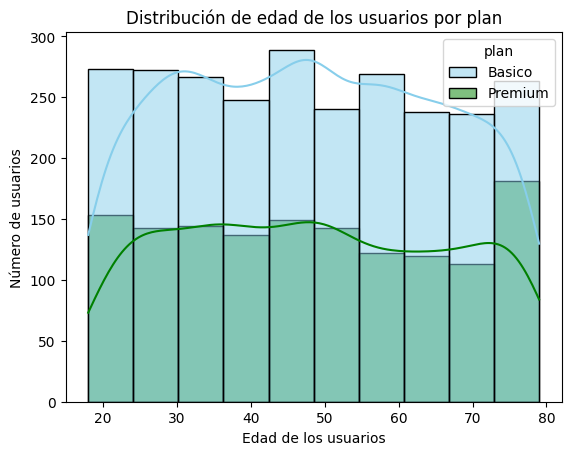

In [112]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
plt.title('Distribución de edad de los usuarios por plan')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Número de usuarios')
plt.show()

<div class="alert alert-block alert-danger">
<b>❌ Comentario del revisor. (Iteración 1) — Necesita arreglos</b> <a class="tocSkip"></a><br>
Los histogramas se generan correctamente, pero falta una parte central del paso: <b>comparar el comportamiento por tipo de plan</b>. Ninguno de los cuatro gráficos distingue entre Básico y Premium, por lo que los insights no pueden responder si existe algún patrón por plan, que es lo que pide el enunciado.<br><br>
Revisa el <i>Hint</i> del paso 5.1: ¿qué parámetro de <code>histplot</code> separa las barras según otra columna? Agrégalo en los cuatro histogramas, junto con la paleta sugerida y un título, y completa cada insight con la comparación entre planes.
</div>

💡Insights: 
- Distribución aplanada, no existen picos y se evidencia variabilidad alta. Los clientes se encuentran entre los 20 y menos de 80 años. Cabe destacar la predominancia de los planes premium en un sector de los usuarios adultos mayores entre los 70 y 80 años, este grupo evidencia la mayor cantidad de planes premium.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Correcta la lectura: distribución aplanada (uniforme), sin picos, en todo el rango de edades.
</div>

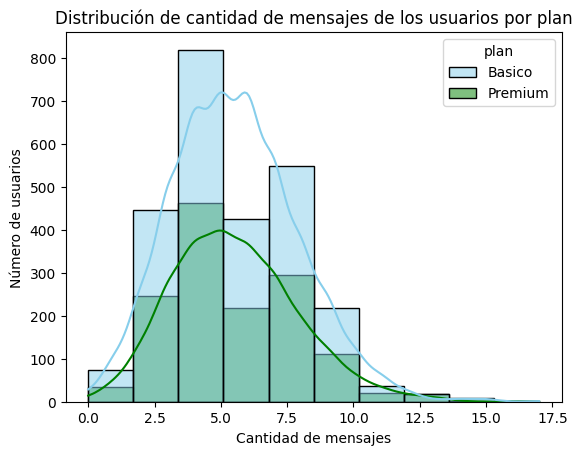

In [113]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
plt.title('Distribución de cantidad de mensajes de los usuarios por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Número de usuarios')
plt.show()


💡Insights: 
- Se evidencia una distribución picuda, con un moderado sesgo a la derecha, el pico más alto se evidencia en los 5 mensajes por usuario.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Bien identificados el sesgo a la derecha y el pico en 5 mensajes.
</div>

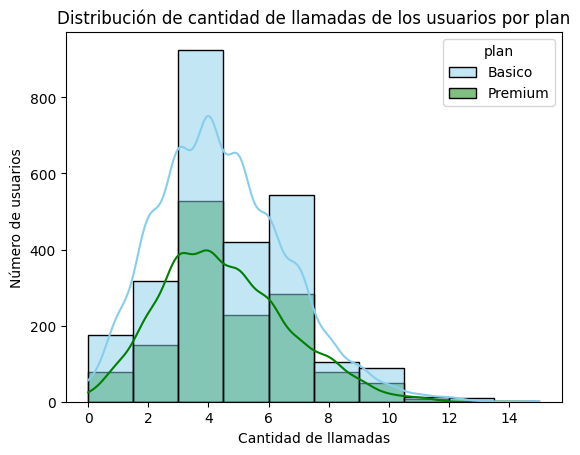

In [114]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
plt.title('Distribución de cantidad de llamadas de los usuarios por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- Distribución picuda, con sesgo moderado a la derecha, el pico más alto se evidencia en las 4 llamadas por usuario para ambos tipos de planes. 

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Interpretación correcta: sesgo moderado a la derecha y pico en 4 llamadas.
</div>

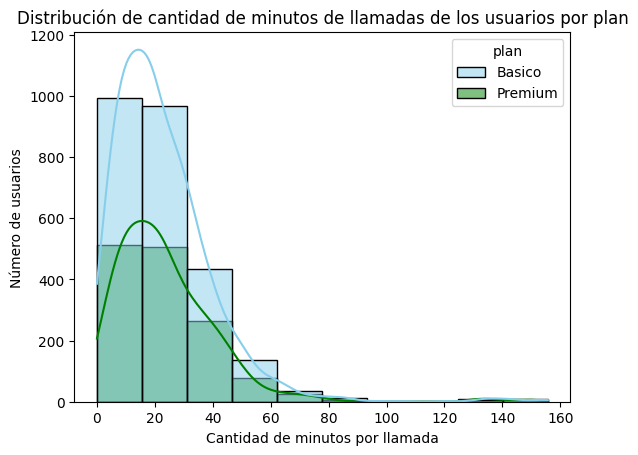

In [115]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=10, palette=['skyblue','green'], kde=True)
plt.title('Distribución de cantidad de minutos de llamadas de los usuarios por plan')
plt.xlabel('Cantidad de minutos por llamada')
plt.ylabel('Número de usuarios')
plt.show()

💡Insights: 
- Se evidencia un marcado sesgo a la derecha, se observa un pico entre los 10 y 20 minutos totales de llamada.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Correcto el sesgo. Precisión: <code>cant_minutos_llamada</code> es el <b>total de minutos acumulados por usuario</b>, no los minutos por llamada. El pico entre 10 y 20 significa que la mayoría de los usuarios suma entre 10 y 20 minutos en total. Ajusta también la etiqueta del eje X.
</div>

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

In [93]:
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

user_profile[columnas_numericas].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000
mean,48.136000,5.523000,4.477000,23.311225
std,17.689919,2.359738,2.145139,18.169564
min,18.000000,0.000000,0.000000,0.000000
1%,18.000000,1.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.107500
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.412500
99%,79.000000,12.000000,10.000000,82.188800
max,79.000000,17.000000,15.000000,155.690000


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Muy buen uso de <code>describe(percentiles=[...])</code> para ver los extremos de cada variable en una sola tabla.
</div>

In [122]:
columnas_numericas = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

Q1 = user_profile[columnas_numericas].quantile(0.25)
Q3 = user_profile[columnas_numericas].quantile(0.75)
IQR = Q3 - Q1

limite_superior = Q3 + 1.5 * IQR

outliers_sup = (user_profile[columnas_numericas] > limite_superior).sum()
print("Valores por encima del IQR")
outliers_sup

Valores por encima del IQR


cant_mensajes            46
cant_llamadas            30
cant_minutos_llamada    109
dtype: int64

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
El texto dice "minutos por llamada", pero la variable es el total por usuario. Además, el percentil 90 deja por encima justo al 10 % de los usuarios por definición, así que el conteo (400) no aporta información nueva; es más útil contar cuántos superan el límite IQR.
</div>

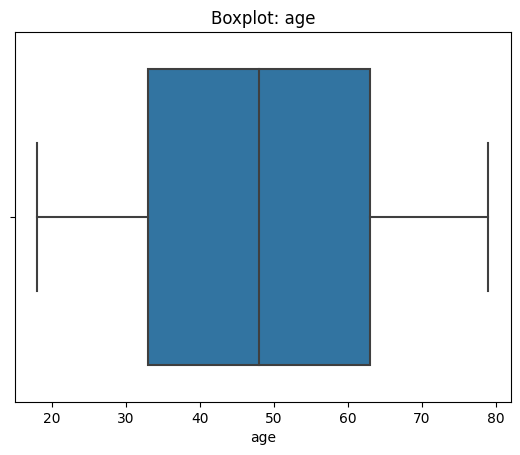

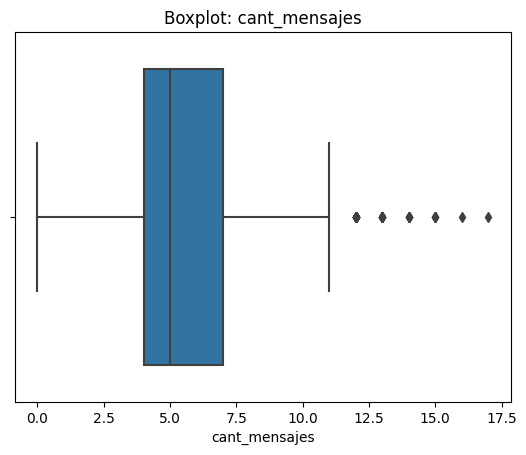

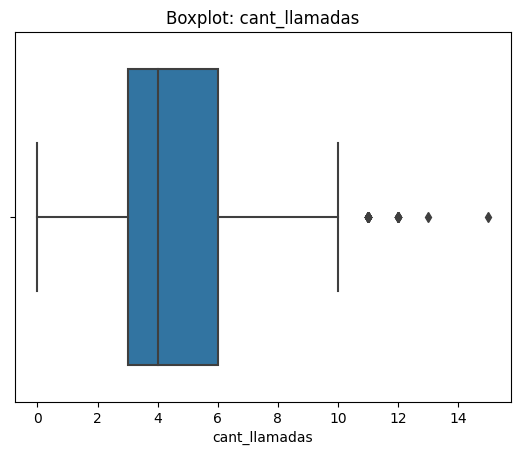

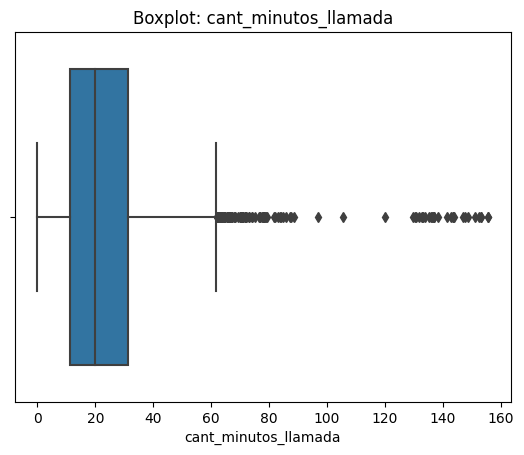

In [95]:
# Visualizando usando BoxPlot 

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure()
    sns.boxplot(data = user_profile, x = col)
    plt.title(f'Boxplot: {col}')
    plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Boxplots generados con un ciclo <code>for</code> y título dinámico, tal como se pedía.
</div>

💡Insights: 
- Age: No presenta outliers, la caja tiene un tamaño normal, al igual que los bigotes que muestran el rango típico de valores. La mediana está en valores medios.
- cant_mensajes: Muestra outliers hacia la derecha y la caja es pequeña. La mediana está en valores bajos, indicativo de que la mayoría de usuarios envía pocos mensajes y un pequeño sector de clientes envía más mensajes que el restante Q4, los outliers son valores altos posibles.
- cant_llamadas: Muestra outliers hacia la derecha, el bigote derecho es ligeramente más amplio y la caja es pequeña. La mediana está en valores bajos, la mayoría de usuarios realiza pocas llamadas. Los outliers son valores altos posibles.
- cant_minutos_llamada: Muestra muchos outliers hacia la derecha, incluyendo outliers extremos, la caja es pequeña y el bigote derecho es más amplio que el izquierdo. La mediana está en valores muy bajos, la mayoría de usuarios realiza llamadas de poca duración. Los outliers son valores altos posibles.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Muy buena interpretación! Describes la caja, los bigotes, la posición de la mediana y el lado de los outliers en cada variable, y concluyes que son valores posibles.
</div>

In [125]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 -Q1
    limite_superior = Q3 + 1.5 * IQR
    print(col, (user_profile[col] > limite_superior).sum(), 'usuarios por encima')
    print(f'{col}: límite superior = {limite_superior}')
    

cant_mensajes 46 usuarios por encima
cant_mensajes: límite superior = 11.5
cant_llamadas 30 usuarios por encima
cant_llamadas: límite superior = 10.5
cant_minutos_llamada 109 usuarios por encima
cant_minutos_llamada: límite superior = 61.870000000000005


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Cálculo IQR correcto, y acertaste al calcular solo el límite superior.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Agrega al ciclo cuántos usuarios superan el límite para dimensionar el grupo de outliers:<br><code>print(col, (user_profile[col] &gt; limite_superior).sum(), 'usuarios por encima')</code>
</div>

In [97]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: 46 usuarios están por encima del límite superior de 11.5 mensajes, mientras el valor máximo son 17 mensajes, 5.5 mensajes por encima del límite superior, mantener outliers, al no ser extremos y poder ser representativo de un segmento de clientes. 
- cant_llamadas: 30 usuarios están por encima del límite superior de 10.5 llamadas realizadas, mientras el valor máximo son 15 llamadas, únicamente 4.5 llamadas por encíma del limite superior. Decisión, mantener outliers, al ser perfectamente posibles, y poder entregar información relevante.
- cant_minutos_llamada: 109 usuarios están por encima del límite superior de 61.8 minutos totales de llamada, mientras el valor máximo son 155.7 minutos totales de llamada, más del doble de minutos del límite superior. Decisión, mantener outliers, a pesar de ser extremos, pueden entregar información valiosa de uso de los planes por segmentos de edad u otros.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Decisión correcta: conservar los outliers porque representan un segmento real de clientes.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Refuerza el argumento con tus números: compara el límite superior con el máximo de cada variable (11.5 vs. 17 mensajes, 10.5 vs. 15 llamadas, 61.9 vs. 155.7 minutos).
</div>

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [129]:
# Crear columna grupo_uso	cant_llamadas	cant_minutos_llamada	

cond_bajo = (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5)
cond_medio = (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)

user_profile['grupo_uso'] = np.where(cond_bajo, 'Bajo uso',
                            np.where(cond_medio, 'Uso medio', 'Alto uso'))

user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
La función de segmentación es clara y respeta el orden de las condiciones.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<code>apply(axis=1)</code> recorre las filas una por una y es lento con datasets grandes. La rúbrica sugiere <code>np.where</code> anidados, que son vectorizados y mucho más rápidos:<br><code>np.where(cond_bajo, 'Bajo uso', np.where(cond_medio, 'Uso medio', 'Alto uso'))</code>
</div>

In [99]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,future_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,False,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN,False,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,False,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,False,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,False,4.0,3.0,8.01,Bajo uso


<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Ojo con los nulos: una comparación con <code>NaN</code> siempre da <code>False</code>. El usuario sin actividad no cumple ninguna condición y la función lo manda al <code>else</code>: <b>"Alto uso"</b>, cuando en realidad no usó el servicio. Por eso cuentas 279 usuarios de alto uso, cuando en realidad son 278. Si rellenas con 0 después del merge, quedará correctamente en "Bajo uso".
</div>

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [100]:
# Crear columna grupo_edad
def age_segment(row) :

    age = row['age']

    if age < 30:
        return "Joven"
    elif age < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad'] = user_profile.apply(age_segment, axis=1)


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Segmentación por edad correcta, con los cortes pedidos.
</div>

In [101]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,future_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01,Basico,NaN,False,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01,Basico,NaN,False,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01,Basico,NaN,False,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01,Premium,NaN,False,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02,Basico,NaN,False,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

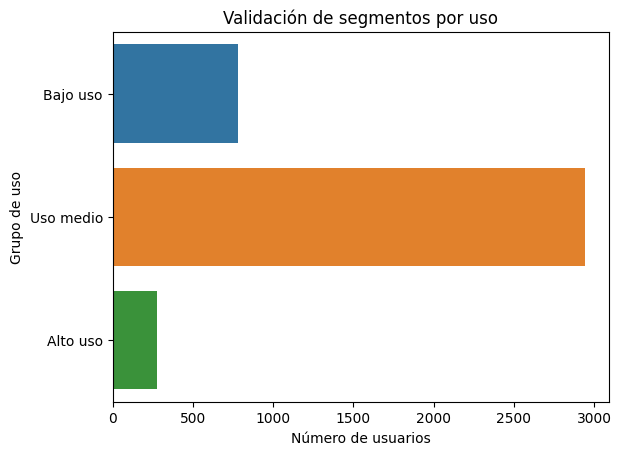

In [131]:
# Visualización de los segmentos por uso

sns.countplot(data = user_profile, y='grupo_uso', order=['Bajo uso','Uso medio','Alto uso'])
plt.ylabel('Grupo de uso')
plt.xlabel('Número de usuarios')
plt.title('Validación de segmentos por uso')
plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Countplot horizontal con título y etiquetas en ambos ejes, y muy bien que verificaste los conteos con <code>value_counts()</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Para categorías con jerarquía natural, un orden lógico se lee mejor que el orden por frecuencia: <code>order=['Bajo uso','Uso medio','Alto uso']</code>.
</div>

In [103]:
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

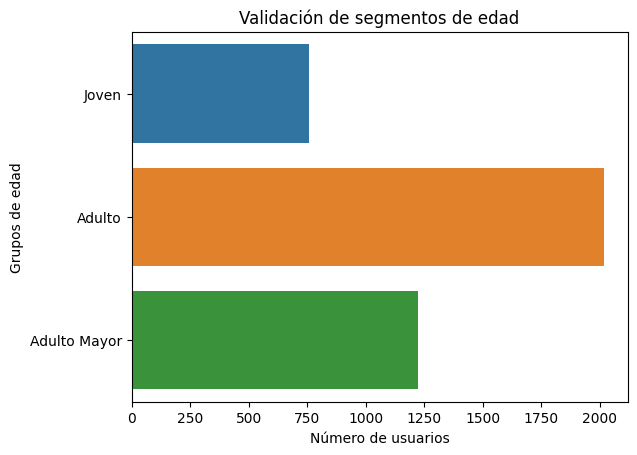

In [132]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, y='grupo_edad', order=['Joven','Adulto','Adulto Mayor'])
plt.ylabel('Grupos de edad')
plt.xlabel('Número de usuarios')
plt.title('Validación de segmentos de edad')
plt.show()


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Gráfico de edad bien rotulado. Ambos countplots cumplen lo pedido.
</div>

In [105]:
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

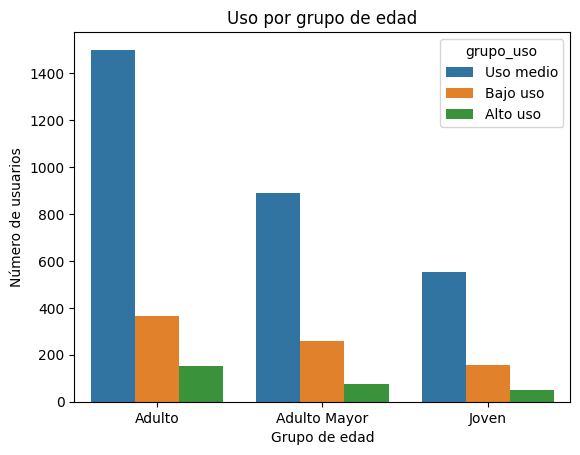

In [106]:

sns.countplot(data=user_profile, x='grupo_edad', hue='grupo_uso', order=user_profile['grupo_edad'].value_counts().index,hue_order=user_profile['grupo_uso'].value_counts().index)
plt.xlabel('Grupo de edad')
plt.ylabel('Número de usuarios')
plt.title('Uso por grupo de edad')
plt.show()


In [133]:
pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index')

grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,0.075818,0.180872,0.743310
Adulto Mayor,0.060556,0.210311,0.729133
Joven,0.067105,0.206579,0.726316


<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
¡Gran valor agregado! 🌟 Cruzaste edad y uso con <code>countplot(hue=...)</code> y <code>pd.crosstab</code>, y luego los grupos de edad por plan. No se pedía y te permite responder cómo se comportan los segmentos.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
Con <code>pd.crosstab(..., normalize='index')</code> verías el <b>porcentaje</b> de cada nivel de uso dentro de cada grupo de edad. Así podrías comparar grupos de distinto tamaño (por ejemplo, si los jóvenes realmente usan menos o simplemente son menos).
</div>

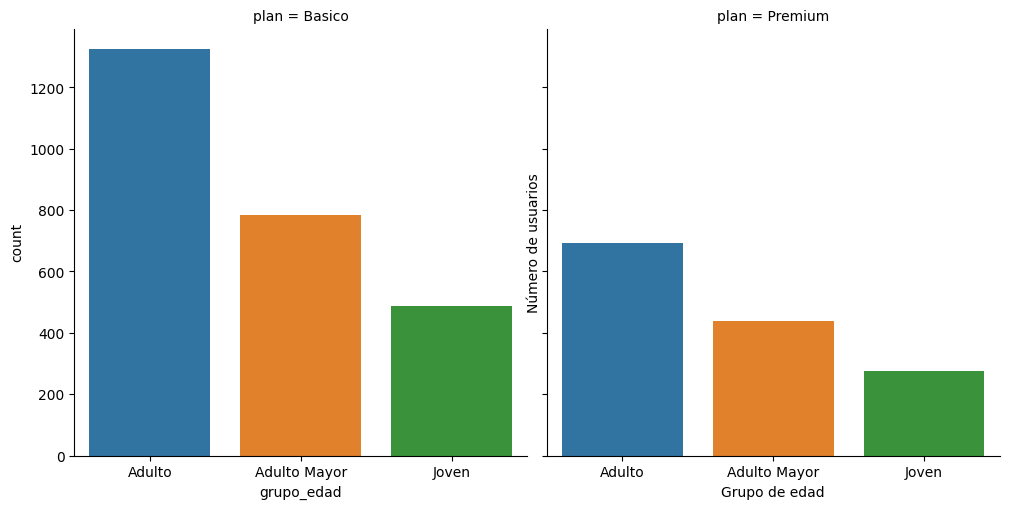

In [108]:
sns.catplot(data=user_profile, x='grupo_edad', col='plan', kind='count', order=user_profile['grupo_edad'].value_counts().index)
plt.ylabel('Número de usuarios')
plt.xlabel('Grupo de edad')
plt.show()

In [109]:
user_profile.value_counts(['plan'])

plan   
Basico     2595
Premium    1405
dtype: int64

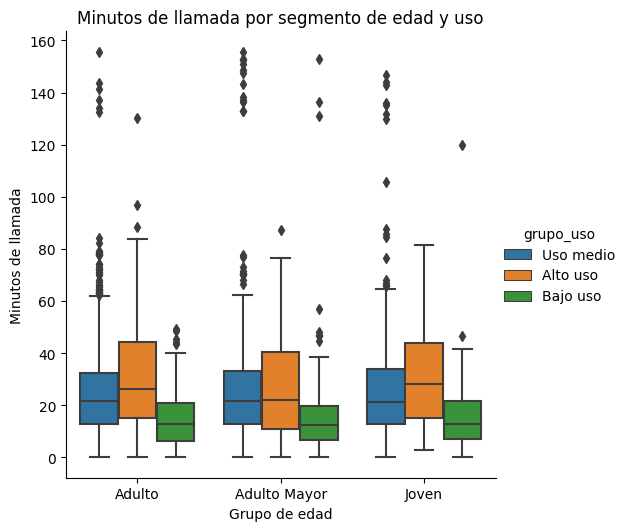

In [134]:
g = sns.catplot(data=user_profile, x='grupo_edad', y='cant_minutos_llamada', hue='grupo_uso', kind='box')
plt.title('Minutos de llamada por segmento de edad y uso')
plt.ylabel('Minutos de llamada')
plt.xlabel('Grupo de edad')
plt.show()

In [ ]:
#En todos los segmentos de edad se evidencia una significativa cantidad de outliers y outliers extremos en minutos de llamada en el grupo de uso medio con casos extremos entre 130 y 155 minutos. Esto sugiere que la segmentación por cantidad de llamadas y mensajes no refleja el consumo real en minutos

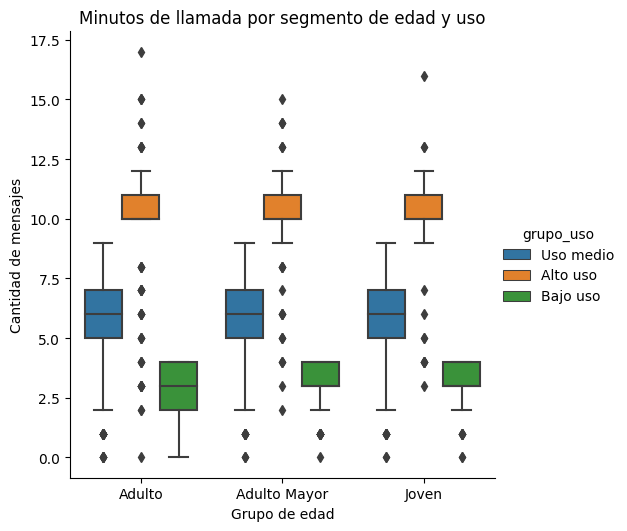

In [137]:
g = sns.catplot(data=user_profile, x='grupo_edad', y='cant_mensajes', hue='grupo_uso', kind='box')
plt.title('Cantidad de mensajes por segmento de edad y uso')
plt.ylabel('Cantidad de mensajes')
plt.xlabel('Grupo de edad')
plt.show()

In [ ]:
#No existe evidencia de que la edad tenga relación con el nivel de uso.

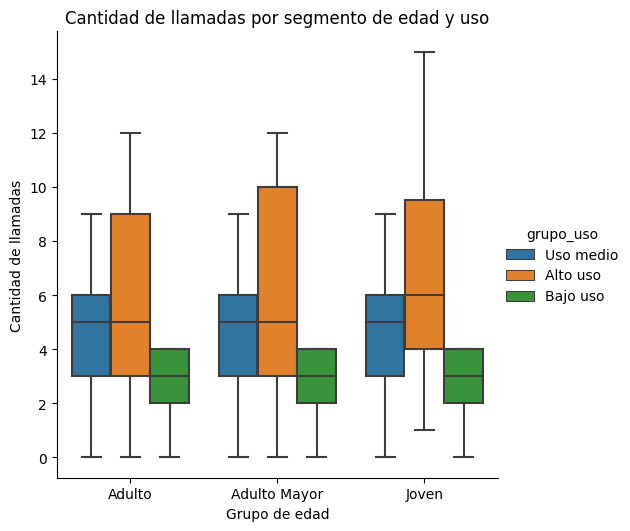

In [138]:
g = sns.catplot(data=user_profile, x='grupo_edad', y='cant_llamadas', hue='grupo_uso', kind='box')
plt.title('Cantidad de llamadas por segmento de edad y uso')
plt.ylabel('Cantidad de llamadas')
plt.xlabel('Grupo de edad')
plt.show()

In [136]:
# En el grupo de alto uso, se evidencia que los jóvenes realizan mayor cantidad de llamadas. En uso medio y bajo uso las distribuciones son prácticamente iguales entre los tres segmentos de edad, por lo que la edad solo parece marcar una diferencia moderada en el segmento de alto uso.

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Buen gráfico exploratorio. Agrégale título y etiquetas en los ejes, igual que al <code>catplot</code> por plan, y una celda con lo que observas: ¿los minutos cambian según el grupo de edad?
</div>


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- **¿Qué problemas tenían originalmemte los datos? ¿Qué porcentaje, o cantidad de filas, de esa columna representaban?**

Inicialmente los datos presentaban valores nulos y outliers,

- users['city']: 469 valores faltantes. (11.7% del total de valores de la columna).
- users['churn_date']: 3534 valores faltantes. (88% del total de valores de la columna).
- usage['date']: 50 valores faltantes. (0.1% del total de valores de la columna).
- usage['duration']: 22076 valores faltantes. (55% del total de valores de la columna). 180 filas con outliers. Expresa missingness dependiente de 'type'.
- usage['lenght']: 17896 valores faltantes. (44.7% del total de valores de la columna). 216 filas con outliers. Expresa missingness dependiente de 'type'.
- users['age']: 55 filas con outliers con valores imposibles (-999). (1.3% del total de valores de la columna).

- **¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?**

Existen 3 segmentos de clientes según su edad: Adulto, Adulto Mayor y Joven. También existen 3 segmentos de clientes según su nivel de uso Alto uso, Bajo uso y uso medio. 
La mayoría de los usuarios expresan un Uso Medio en todos los segmentos de edad y en general, adicionalmente los jovenes son el segmento más pequeño. En todos los segmentos de uso, los adultos representan a la mayoría de los usuarios. Adicionalmente el plan más contratado es el básico y es mayormente contratrado por adultos, al igual que el plan premium.

- **¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?**

Los adultos, estos representan la mayor porción de clientes de ConnectaTel, además de esto, también son quienes más contratan planes premium además de mostrar un uso más alto de los planes, por lo cual se pueden crear planes orientados a las necesidades de este segmento.
  
- **¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?**

En la duración de las llamadas se aprecia un valor máximo de 155.690000, casi 7 veces la mediana (23). Se evidencian outliers extremos significativos en los 3 segmentos de edades en la duración de las llamadas para los grupos de uso medio, por lo que se puede adaptar una solución o producto que genere mayor rentabilidad de este segmento de clientes.

- **¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?**

Crear planes orientados a clientes adultos y adultos mayores, segmentando por sus tipos de consumo, reevaluando la oferta y beneficios incluidos en los planes básicos y premium, para motivar la migración de clientes de planes básicos a planes premium, por ejemplo, ofreciendo mayor cantidad de tiempo de llamada a los clientes premium o limitando algunos de los beneficios en los planes básicos para hacer más atractiva la oferta de los planes premium. 

✍️ **Escribe aquí tu análisis ejecutivo:**

Contexto, objetivo y cobertura de datos: Análisis de los patrones de uso de servicios y planes de telefonía para detectar comportamientos atípicos y comprender que segmentos de clientes muestran necesidades diferenciadas, con el fin de optimizar la oferta comercial y mejorar la experiencia del usuario. Partiendo de los dos segmentos: Grupo de edad (joven, usuarios menores a 30 años; adulto, usuarios menores a 60 años; adultos mayores, usuarios a partir de los 60 años). Segmento de uso (Bajo uso, menos de 5 llamadas y 5 mensajes. Uso medio, menos de 10 llamadas y 10 mensajes. Alto uso, a partir de 10 llamadas y 10 mensajes).


El segmento de uso más predominante es el de Uso Medio, con 2943 usuarios, más de la mitad del total de usuarios, el uso Alto es el de menor recurrencia, con 279 usuarios. En cuanto a la edad, la mayoria de los usuarios son Adultos (2018), seguido por los adultos mayores (1222) y por último la menor porción de los usuarios son jovenes (760). Respecto al uso, el 99% de los usuarios envían entre 1 y 12 mensajes, realizan entre 0 y 10 llamadas y la duración de las llamadas está entre 0 y 82 minutos.

En el uso medio, podemos apreciar outliers extremos en los minutos por llamada, dichos outliers son muy significativos si se considera que el uso alto presenta muy pocos outliers extremos entre todos los segmentos de edad. Esto puede significar que en los usuarios de uso medio tenemos un sector de clientes con un volumen alto de minutos, a este sector se puede apuntar para aumentar la venta de planes premium, evaluando la posibilidad de diferenciar las ofertas de minutos entre el plan básico y el plan premium, limitando los minutos que se ofrecen en el plan básico a un límite que no afecte al percentil 90 de los usuarios, serían 400 usuarios que se puede proyectar rentabilizar partiendo de los minutos por llamada. 
Adicionalmente, los adultos siendo el segmento predominante debe ser priorizado en futuras campañas en todos los segmentos de uso, enfocar más recursos al crecimiento del alto uso mediante el mejoramiento de la calidad de las llamadas e impulsando mejoras o innovaciones en los servicios de mensajería que impulsen el uso de estos servicios en el segmento de adultos.



### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- users['city']: Contiene 96 sentinels (?), luego del reemplazo de los sentinels por valores nulos, el total de nulos es 565.
- users['churn_date']: 3534 valores faltantes. (88% del total de valores de la columna).
- usage['date']: 50 valores faltantes. (0.1% del total de valores de la columna).
- usage['duration']: Expresa missingness dependiente de 'type', los valores nulos solo se expresan en "text" ya que los mensajes de texto se miden en caracteres en la columna 'length'.
- usage['lenght']: Expresa missingness dependiente de 'type', los valores nulos solo se expresan en "call" ya que 'length' mide el largo de los mensajes de texto basado en el número de caracteres mientras 'length' mide la longitud (duración) de las llamadas en minutos.
- users['age']: 55 filas con outliers con valores imposibles (-999). (1.3% del total de valores de la columna).


🔍 **Segmentos por Edad**

- Joven, ususarios menores a 30 años. Es el segmento con menor volumen de usuarios, 760 en total, poco menos de la mitad de usuarios adultos del segmento de uso medio.
- Adulto, usuarios menores a 60 años. Es el segmento con mayor volumen de usuarios en todos los niveles de uso, alto uso con 154, bajo uso 364 y uso medio, el uso de mayor volumen 1500. Para un total de 2018 usuarios.
- Adulto Mayor, usuarios mayores a 60 años. Número de usuarios: 1222.


📊 **Segmentos por Nivel de Uso**

- Bajo uso, menos de 5 mensajes y menos de 5 llamadas. 779 usuarios.
- Uso medio, menos de 10 mensajes y menos de 10 llamadas. 2943 usuarios.
- Alto uso, 10 mensajes o más o 10 llamadas o más. 278 usuarios.

➡️ Esto sugiere que el segmento de edad más importante es el de los adultos y el segmento más importante en nivel de uso es el uso medio, ambos segmentos están significativamente por encima del resto de su categoría. La diferencia en volumen de usuarios también sugiere que el segmento joven no se siente atraído por la oferta actual, reportando los valores más pequeños en todos los segmentos de uso, lo que podría dar lugar a crecimiento en caso de ofrecer soluciones tecnológicas atractivas adaptadas al segmento joven. 


💡 **Recomendaciones**
- Ofrecer un plan con más minutos incluidos a los usuarios atípicos en minutos de llamada. Un grupo pequeño principalmente de medio uso supera ampliamente el consumo típico, con llamadas de hasta 155 minutos. Evaluar migrarlos a un plan superior que mejore su experiencia.
- Diseñar la oferta por nivel de uso y no por edad al no evidenciar cambios en el consumo segun los grupos de edad, exceptuando una ligera tendencia de los jóvenes de alto uso a llamar más. Evaluar la segmentación de campañas y planes según uso.

In [ ]:
## Hola Santiago, muchisimas gracias por el tiempo para la revisión y la dedicación en el feedback, me siento mucho más conforme con esta versión del proyecto.

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Buen resumen ejecutivo: cuantificas los problemas de nulos, describes cada segmento con su tamaño y usas tu <code>crosstab</code> para mostrar cómo se reparten los niveles de uso dentro de los Adultos.
</div>

<div class="alert alert-block alert-warning">
<b>⚠️ Comentario del revisor. (Iteración 1) — Recomendación</b> <a class="tocSkip"></a><br>
Para completarlo:
<ul>
<li><b>Problemas:</b> faltan el sentinel <code>"?"</code> en <code>city</code> (96) y las 40 fechas de 2026. Recuerda que los nulos de <code>duration</code>/<code>length</code> no son outliers, y que el <code>-999</code> es un sentinel, no un outlier.</li>
<li><b>Definición de Alto uso:</b> no es "10 mensajes o más <b>y</b> 10 llamadas o más", sino 10 o más en <b>al menos una</b> de las dos (el resto de los casos).</li>
<li><b>Segmento joven:</b> que haya menos jóvenes no implica por sí solo que la oferta no les atraiga. Revisa el porcentaje de cada nivel de uso por grupo de edad para ver si los jóvenes realmente usan menos.</li>
<li><b>Premium:</b> la recomendación de migrar usuarios al Premium necesita respaldo. Con <code>hue='plan'</code> en los histogramas podrás ver si los clientes Premium usan más el servicio que los Básico.</li>
<li><b>Outliers:</b> la pregunta pide qué patrones de uso extremo encontraste y qué implican para el negocio.</li>
</ul>
</div>

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí` https://github.com/frankgc23/analysis-ConnectaTel

<div class="alert alert-block alert-success">
<b>✅ Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a><br>
Link al repositorio incluido. Asegúrate de que el repo tenga el notebook y un <code>README.md</code> con objetivo, datasets, etapas del análisis y cómo ejecutarlo. Borra el texto de la plantilla <code>`LINK a tu repo aquí`</code>.
</div>

<div class="alert alert-block alert-info">
<b>💡 Comentario del revisor. (Iteración 1) — Tip de eficiencia</b> <a class="tocSkip"></a><br>
<b>📊 Evaluación según la rúbrica DA Sprint 7</b><br><table><tr><th>Parte</th><th>Criterio</th><th>Estado</th></tr><tr><td>1. Carga y exploración</td><td>Librerías, carga, head/info/shape</td><td>✅</td></tr><tr><td>2. Calidad de datos</td><td>Nulos (conteo y proporción)</td><td>✅</td></tr><tr><td></td><td>Sentinels (-999 y "?")</td><td>✅</td></tr><tr><td></td><td>Fechas (errors='coerce', revisión por año)</td><td>✅</td></tr><tr><td></td><td>Diagnóstico escrito</td><td>🟡 cifras y acciones a ajustar</td></tr><tr><td>3. Limpieza</td><td>Mediana en age + validación</td><td>✅ (sugerencia: excluir sentinel)</td></tr><tr><td></td><td>"?" → pd.NA</td><td>🟡 reemplazado por el texto "NA"</td></tr><tr><td></td><td>Fechas imposibles → nulo</td><td>🟡 708 fechas nulas en lugar de 40</td></tr><tr><td></td><td>Evaluación MAR</td><td>✅</td></tr><tr><td></td><td>Decisión justificada</td><td>🟡 sin conclusión ni decisión</td></tr><tr><td>4. Uso por usuario</td><td>Agrupación, métricas y merge</td><td>✅ (sugerencia: fillna(0))</td></tr><tr><td></td><td>Revisión estadística</td><td>🟡 info() en lugar de describe()</td></tr><tr><td>5. Distribuciones y outliers</td><td>Histogramas</td><td>✅</td></tr><tr><td></td><td>Comparación por plan (hue='plan')</td><td>❌ no se compara por plan</td></tr><tr><td></td><td>Interpretación</td><td>✅</td></tr><tr><td></td><td>Boxplots e IQR</td><td>✅</td></tr><tr><td>6. Segmentación</td><td>grupo_uso / grupo_edad</td><td>✅ (ojo con NaN → Alto uso)</td></tr><tr><td></td><td>Countplots rotulados</td><td>✅</td></tr><tr><td>7. Insight ejecutivo</td><td>Segmentos y comportamiento</td><td>✅</td></tr><tr><td></td><td>Segmentos valiosos y recomendaciones</td><td>🟡 sin respaldo en datos</td></tr><tr><td>8. Publicación</td><td>Link al repositorio</td><td>✅ (notebook y README a verificar)</td></tr></table><br>Un criterio en ❌ → <b>proyecto devuelto para una nueva iteración</b>.
</div>

<div class="alert alert-block alert-info">
<b>Comentario del revisor. (Iteración 1) — Próximos pasos</b> <a class="tocSkip"></a><br><br>
Frank, tu proyecto tiene muy buen nivel exploratorio y está cerca de la aprobación. Para la siguiente iteración, el único punto bloqueante ❌ es:
<ol><li><b>Paso 5.1:</b> comparar los planes en los cuatro histogramas y agregar esa comparación a cada insight.</li></ol>
En la siguiente iteración revisaré únicamente este punto, así que no habrá requisitos nuevos. Las recomendaciones 🟡 son opcionales, aunque te sugiero especialmente: reemplazar el <code>"?"</code> por un nulo real, ajustar el límite de fechas para marcar solo las 40 de 2026, escribir la conclusión MAR con su decisión y completar el resumen ejecutivo.<br><br>
¡Ánimo, ya casi está! 💪
</div>